In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import eu9_osm
from shapely import voronoi_polygons
from shapely.geometry import MultiPoint, box
from matplotlib.patches import Patch

In [2]:
# Points
df = pd.read_csv("points.csv")
gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df["longitude"], df["latitude"]), crs="EPSG:4326").to_crs("EPSG:3763")

In [3]:
# Map extent
bbox = (
    -9.145002526853894,
    38.70590725593771,
    -9.133598206390193,
    38.71582096558039
)

bbox_gdf = gpd.GeoSeries([box(*bbox)], crs="EPSG:4326").to_crs("EPSG:3763")
minx, miny, maxx, maxy = bbox_gdf.total_bounds
boundary = box(minx, miny, maxx, maxy)

In [4]:
# OSM
roads = eu9_osm.features_from_bbox(bbox=bbox, tags={"highway": True}, clip=True).to_crs("EPSG:3763")
buildings = eu9_osm.features_from_bbox(bbox=bbox, tags={"building": True}, clip=True).to_crs("EPSG:3763")

roads = roads[roads.geometry.geom_type.isin(["LineString", "MultiLineString"])]
buildings = buildings[buildings.geometry.geom_type.isin(["Polygon", "MultiPolygon"])]

In [5]:
# Generate Voronoi polygons
vor = voronoi_polygons(MultiPoint(gdf.geometry.tolist()), extend_to=boundary)

# Convert to GeoDataFrame
vor_gdf = gpd.GeoDataFrame(geometry=list(vor.geoms), crs=gdf.crs)

# Associate each polygon with its nearest historical point
vor_gdf["source_idx"] = (vor_gdf.geometry.representative_point().apply(lambda p: gdf.geometry.distance(p).idxmin()))

vor_gdf = vor_gdf.join(gdf.drop(columns="geometry"), on="source_idx")

# Clip to rectangular boundary
vor_gdf = gpd.clip(vor_gdf, boundary)

In [6]:
palette = [
    "#557C91",  # Fish & Brine
    "#82A6A0",  # Fresh Seafood
    "#B85C58",  # Blood & Offal
    "#D28A72",  # Spices & Trade
    "#D6BC83",  # Flour & Grain
    "#777D91",  # Charcoal & Smoke
    "#B49A72",  # Cargo & Spices
    "#879477",  # Timber & Wood
    "#496F68",  # Timber & Pitch
    "#A18DAA"   # Incense & Wax
]

# Unique smell descriptions
smells = gdf["smell"].drop_duplicates().tolist()

colors = dict(zip(smells, palette))

# Short legend labels
smell_labels = {
    "Fish, brine, fish waste": "Fish & Brine",
    "Fresh fish, seafood, wet baskets": "Fresh Seafood",
    "Blood, offal, animal fat": "Blood & Offal",
    "Spices, food, leather, mixed goods": "Spices & Trade",
    "Flour, grain, cereals, bread": "Flour & Grain",
    "Charcoal, forge smoke, heated metal": "Charcoal & Smoke",
    "Cargo, spices, stored goods": "Cargo & Spices",
    "Timber, wood shavings": "Timber & Wood",
    "Timber, pitch, smoke": "Timber & Pitch",
    "Incense, candle wax, gatherings": "Incense & Wax"
}

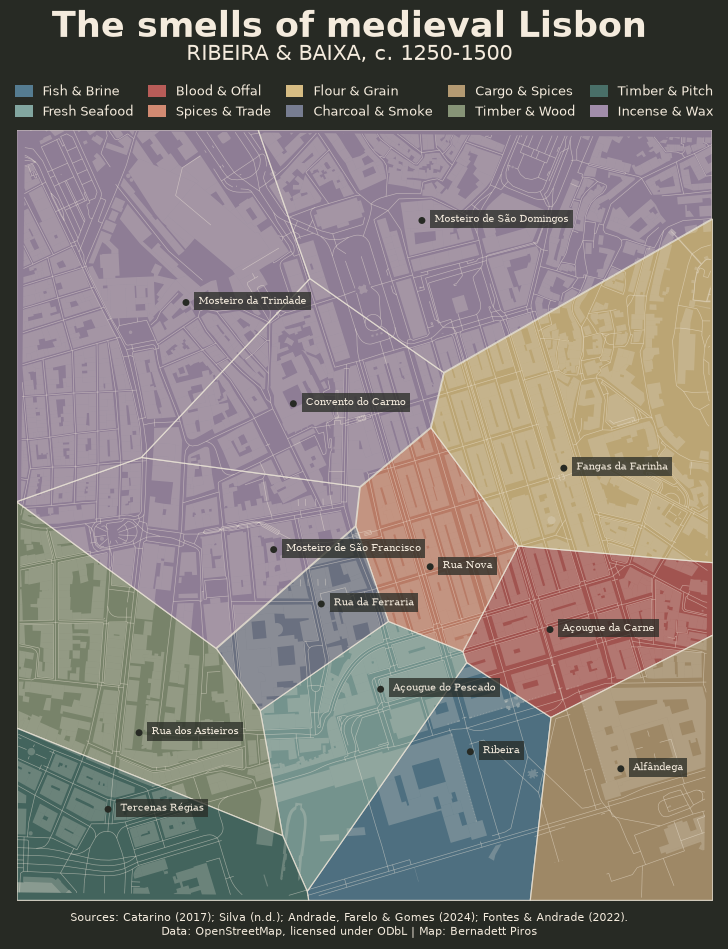

In [7]:
fig, ax = plt.subplots(figsize=(12, 10), facecolor="#272a24")

# Voronoi
for smell, color in colors.items():
    subset = vor_gdf[vor_gdf["smell"] == smell]
    subset.plot(ax=ax, color=color, ec="#E8E1D4", lw=0.85, alpha=0.85, zorder=1)

# Buildings
buildings.plot(ax=ax, color="#E6E0D4", ec="none", alpha=0.25, zorder=2)

# Roads
roads.plot(ax=ax, color="#F4EBDD", lw=0.45, alpha=0.5, zorder=3)

# Points
gdf.plot(ax=ax, color="#272a24", ec="none", markersize=25, zorder=5)

ax.set_facecolor("#272a24")
ax.set_xlim(minx, maxx)
ax.set_ylim(miny, maxy)
ax.set_aspect("equal")
ax.axis("off")

# Labels
for i, row in gdf.iterrows():

    ax.text(row.geometry.x+18, row.geometry.y-2, row["name"], color="#F4EBDD",
            size=7, fontfamily="DejaVu Serif", bbox=dict(facecolor="#272a24", ec="none", alpha=0.75, pad=3), zorder=6)

# Legend
handles = [Patch(facecolor=colors[smell], ec="none", label=smell_labels[smell]) for smell in smells]

legend = ax.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 1), ncol=5, frameon=False,
                   labelcolor="#F4EBDD", fontsize=9, columnspacing=1.2, handlelength=1.4, handleheight=1.1)

# Title
fig.text(0.5, 1,
         "The smells of medieval Lisbon",
         color="#F4EBDD", size=25, weight="bold", ha="center", va="top")

fig.text(0.5, 0.95, 
         "RIBEIRA & BAIXA, c. 1250-1500",
         color="#F4EBDD", size=15, ha="center")

fig.text(
    0.5, 0.075,
    "Sources: Catarino (2017); Silva (n.d.); Andrade, Farelo & Gomes (2024); Fontes & Andrade (2022).\n"
    "Data: OpenStreetMap, licensed under ODbL | Map: Bernadett Piros",    
    color="#F4EBDD", size=8, ha="center")
 
plt.show()

#fig.savefig("medieval_smells.png", bbox_inches="tight", pad_inches=0.2) 